# Train the character projection MLP
Use **Godfather**. GPU training reads `training_data.pt`. Save **one checkpoint**, `character_identity_mlp.pt`. No extra logs or model variants are written.

Use the original cosine contrastive loss, with dropout, AdamW, and learning-rate reduction. Select the best epoch by validation balanced accuracy, with validation loss as the tie-breaker. Test data is not used for any training choice.


## 1. Settings
Input normalization is an explicit experiment setting: start with `NORMALIZE_INPUT=True`; set it to False for a controlled comparison. Keep data, seed, and other settings fixed. Re-running replaces the one checkpoint, so compare notebook results before replacing it.


In [9]:
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from pathlib import Path
import hashlib
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path('C:/Users/ESHAAN/BYTE/Applied-Task/Magi/charSimilarityMLP')
DATA_FILE = ROOT / 'training_data.pt'
MODEL_FILE = ROOT / 'character_identity_mlp.pt'
SEED, BATCH_SIZE, EPOCHS, PATIENCE = 42, 256, 50, 30
LEARNING_RATE, WEIGHT_DECAY, DROPOUT, MARGIN = 3e-4, 1e-4, 0.1, 0.2
NORMALIZE_INPUT = True
assert torch.cuda.is_available(), 'Use Godfather with CUDA-enabled PyTorch.'
device = torch.device('cuda:0')
torch.manual_seed(SEED)
data = torch.load(DATA_FILE, map_location='cpu', weights_only=True)
assert data['version'] == 2
with DATA_FILE.open('rb') as file:
    data_hash = hashlib.file_digest(file, 'sha256').hexdigest()
assert not (set(data['splits']['train']) & set(data['splits']['validation']) or
            set(data['splits']['train']) & set(data['splits']['test']) or
            set(data['splits']['validation']) & set(data['splits']['test']))
print('GPU:', torch.cuda.get_device_name(device))

class PairDataset(Dataset):
    def __init__(self, split):
        self.rows = data['pairs'][split]
        assert len(self.rows) and set(self.rows[:, 3].tolist()) == {0, 1}

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        i, a, b, label = self.rows[index].tolist()
        s = data['sequences'][i]
        return s['embeddings'][a], s['embeddings'][b], torch.tensor(label, dtype=torch.float32)

loaders = {split: DataLoader(PairDataset(split), batch_size=BATCH_SIZE,
                            shuffle=split == 'train', num_workers=0, pin_memory=True)
           for split in ['train', 'validation']}
for split in loaders:
    print(split, '| pairs:', len(loaders[split].dataset))


GPU: NVIDIA GeForce RTX 4060 Laptop GPU
train | pairs: 2210
validation | pairs: 693


## 2. Model and unchanged loss
The margin is a training setting, not an identity decision threshold. Normalized outputs use dot product as cosine. Positive loss is `1-s`; negative loss is `max(0,s-margin)`.


In [10]:
class OFRmlpModel(nn.Module):
    def __init__(self, dropout=0.1, normalize_input=True):
        super().__init__()
        self.normalize_input = normalize_input
        self.net = nn.Sequential(nn.Linear(768, 256), nn.ReLU(),
                                 nn.Dropout(dropout), nn.Linear(256, 128))

    def forward(self, x):
        if self.normalize_input:
            x = F.normalize(x, dim=-1)
        return F.normalize(self.net(x), dim=-1)

def contrastive_cosine_loss(z1, z2, labels):
    similarity = (z1 * z2).sum(dim=-1).clamp(-1, 1)
    return (labels * (1-similarity) +
            (1-labels) * (similarity-MARGIN).clamp(min=0)).mean()

model = OFRmlpModel(DROPOUT, NORMALIZE_INPUT).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=2, threshold=0.0)


## 3. Validation metrics and thresholds
Search observed validation score boundaries rather than a coarse fixed grid. Select thresholds on validation only. Class recalls and cross-page metrics reveal problems hidden by overall loss.


In [11]:
def metrics(scores, labels, threshold):
    predicted = scores >= threshold
    positive, negative = labels == 1, labels == 0
    same = float(predicted[positive].mean()) if positive.any() else float('nan')
    different = float((~predicted[negative]).mean()) if negative.any() else float('nan')
    return dict(balanced_accuracy=(same + different) / 2,
                same_recall=same, different_recall=different,
                accuracy=float((predicted == labels).mean()) if len(labels) else float('nan'))

def choose_threshold(scores, labels):
    # Check all distinct score boundaries efficiently, including predicting nobody SAME.
    assert set(labels.tolist()) == {0, 1}
    order = np.argsort(-scores, kind='stable')
    values, targets = scores[order], labels[order]
    ends = np.r_[np.where(values[:-1] != values[1:])[0], len(values)-1]
    tp = np.cumsum(targets)[ends]
    fp = (ends + 1) - tp
    balanced = (tp / targets.sum() + 1 - fp / (len(targets)-targets.sum())) / 2
    best = int(np.argmax(balanced))
    return float(values[ends[best]]) if balanced[best] > 0.5 else float(np.nextafter(float(values[0]), np.inf))

@torch.inference_mode()
def validation_scores():
    model.eval()
    raw, projected, labels = [], [], []
    for a, b, y in loaders['validation']:
        a, b = a.to(device), b.to(device)
        raw.append(F.cosine_similarity(a, b).cpu().numpy())
        projected.append((model(a) * model(b)).sum(dim=-1).clamp(-1, 1).cpu().numpy())
        labels.append(y.numpy())
    rows = data['pairs']['validation']
    cross = np.array([int(data['sequences'][i]['page'][a]) != int(data['sequences'][i]['page'][b])
                      for i, a, b, _ in rows.tolist()])
    return np.concatenate(raw), np.concatenate(projected), np.concatenate(labels), cross

def run_epoch(training):
    model.train(training)
    totals = np.zeros(3)
    counts = np.zeros(3)
    with torch.set_grad_enabled(training):
        for a, b, labels in loaders['train' if training else 'validation']:
            a, b, labels = [x.to(device, non_blocking=True) for x in (a, b, labels)]
            if training:
                optimizer.zero_grad()
            z1, z2 = model(a), model(b)
            loss = contrastive_cosine_loss(z1, z2, labels)
            if training:
                loss.backward()
                optimizer.step()
            with torch.no_grad():
                similarity = (z1 * z2).sum(dim=-1).clamp(-1, 1)
                positive, negative = labels == 1, labels == 0
                totals += [loss.item() * len(labels), (1-similarity[positive]).sum().item(),
                           (similarity[negative]-MARGIN).clamp(min=0).sum().item()]
                counts += [len(labels), positive.sum().item(), negative.sum().item()]
    return tuple(float(value) for value in totals / np.maximum(counts, 1))


## 4. Train and save the best checkpoint
Train up to 50 epochs, reduce LR on validation-loss plateaus, and stop after 10 epochs without improved validation balanced accuracy (loss breaks exact ties). Keep dropout disabled during validation. Validation tuning can itself overfit; use the test notebook only after selecting the experiment.


01 | train=0.3907 | val=0.4784 | val_pos=0.0674 | val_neg=0.6866 | BA=0.704 | cross_BA=0.709 | lr=0.0003
02 | train=0.3370 | val=0.3063 | val_pos=0.3079 | val_neg=0.3056 | BA=0.682 | cross_BA=0.691 | lr=0.0003
03 | train=0.3014 | val=0.3275 | val_pos=0.2654 | val_neg=0.3589 | BA=0.662 | cross_BA=0.687 | lr=0.0003
04 | train=0.2861 | val=0.3201 | val_pos=0.2696 | val_neg=0.3457 | BA=0.661 | cross_BA=0.695 | lr=0.0003
05 | train=0.2738 | val=0.3080 | val_pos=0.2920 | val_neg=0.3160 | BA=0.666 | cross_BA=0.683 | lr=0.0003
06 | train=0.2651 | val=0.3088 | val_pos=0.3009 | val_neg=0.3128 | BA=0.665 | cross_BA=0.675 | lr=0.00015
07 | train=0.2596 | val=0.3063 | val_pos=0.3031 | val_neg=0.3079 | BA=0.673 | cross_BA=0.690 | lr=0.00015
08 | train=0.2562 | val=0.2992 | val_pos=0.3113 | val_neg=0.2930 | BA=0.677 | cross_BA=0.685 | lr=0.00015
09 | train=0.2506 | val=0.3042 | val_pos=0.3049 | val_neg=0.3038 | BA=0.680 | cross_BA=0.694 | lr=0.00015
10 | train=0.2476 | val=0.2986 | val_pos=0.3218 | v

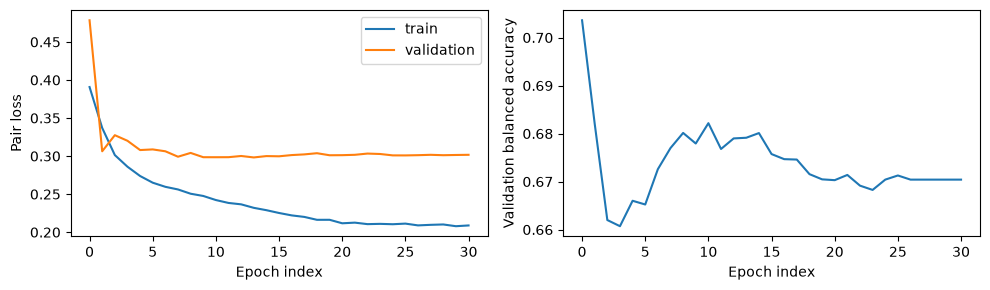

Best epoch: 1 | validation metrics: {'balanced_accuracy': 0.7036060832244821, 'same_recall': 0.6137339055793991, 'different_recall': 0.7934782608695652, 'accuracy': 0.733044733044733}
Saved one checkpoint: C:\Users\ESHAAN\BYTE\Applied-Task\Magi\charSimilarityMLP\character_identity_mlp.pt


In [12]:
best_accuracy, best_loss, bad_epochs = -1.0, float('inf'), 0
history = []
for epoch in range(1, EPOCHS + 1):
    train_loss, _, _ = run_epoch(True)
    val_loss, val_positive, val_negative = run_epoch(False)
    val_loss = float(val_loss)  # Save a Python float, not a NumPy scalar.
    assert np.isfinite(train_loss) and np.isfinite(val_loss)
    raw, projected, labels, cross = validation_scores()
    threshold = choose_threshold(projected, labels)
    result = metrics(projected, labels, threshold)
    cross_result = metrics(projected[cross], labels[cross], threshold)
    lr = optimizer.param_groups[0]['lr']
    history.append((train_loss, val_loss, result['balanced_accuracy']))
    print(f"{epoch:02d} | train={train_loss:.4f} | val={val_loss:.4f} | val_pos={val_positive:.4f} | val_neg={val_negative:.4f} | BA={result['balanced_accuracy']:.3f} | cross_BA={cross_result['balanced_accuracy']:.3f} | lr={lr:.2g}")
    scheduler.step(val_loss)
    accuracy = result['balanced_accuracy']
    if accuracy > best_accuracy or (accuracy == best_accuracy and val_loss < best_loss):
        best_accuracy, best_loss, bad_epochs = accuracy, val_loss, 0
        saved = dict(version=2, model_state={k: v.detach().cpu() for k, v in model.state_dict().items()},
                     model_config=dict(dropout=DROPOUT, normalize_input=NORMALIZE_INPUT),
                     training=dict(seed=SEED, margin=MARGIN, learning_rate=LEARNING_RATE,
                                   weight_decay=WEIGHT_DECAY, batch_size=BATCH_SIZE),
                     epoch=epoch, validation_loss=val_loss, validation_metrics=result,
                     threshold=threshold, raw_threshold=choose_threshold(raw, labels),
                     data_hash=data_hash)
        torch.save(saved, MODEL_FILE)
    else:
        bad_epochs += 1
        if bad_epochs >= PATIENCE:
            print('Early stopping.')
            break

saved = torch.load(MODEL_FILE, map_location='cpu', weights_only=True)
model.load_state_dict(saved['model_state'])
model.eval()
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].plot([h[0] for h in history], label='train')
axes[0].plot([h[1] for h in history], label='validation')
axes[0].set(xlabel='Epoch index', ylabel='Pair loss'); axes[0].legend()
axes[1].plot([h[2] for h in history])
axes[1].set(xlabel='Epoch index', ylabel='Validation balanced accuracy')
plt.tight_layout(); plt.show()
print('Best epoch:', saved['epoch'], '| validation metrics:', saved['validation_metrics'])
print('Saved one checkpoint:', MODEL_FILE)
